In [2]:
import networkx as nx
import numpy as np

G = nx.read_edgelist(
    "twitter.txt",
    nodetype=int
)

G.remove_edges_from(nx.selfloop_edges(G))

degrees = np.array([d for _, d in G.degree()])

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Connected components:", nx.number_connected_components(G))

print("\nDegree statistics:")
print("Mean:", degrees.mean())
print("Median:", np.median(degrees))
print("Min:", degrees.min())
print("Max:", degrees.max())

print("\nDegree percentiles:")
for p in [25, 50, 75, 90, 95, 99]:
    print(f"{p}%:", np.percentile(degrees, p))

Nodes: 81306
Edges: 1342296
Connected components: 1

Degree statistics:
Mean: 33.01837502767324
Median: 15.0
Min: 1
Max: 3383

Degree percentiles:
25%: 5.0
50%: 15.0
75%: 37.0
90%: 76.0
95%: 117.0
99%: 264.0


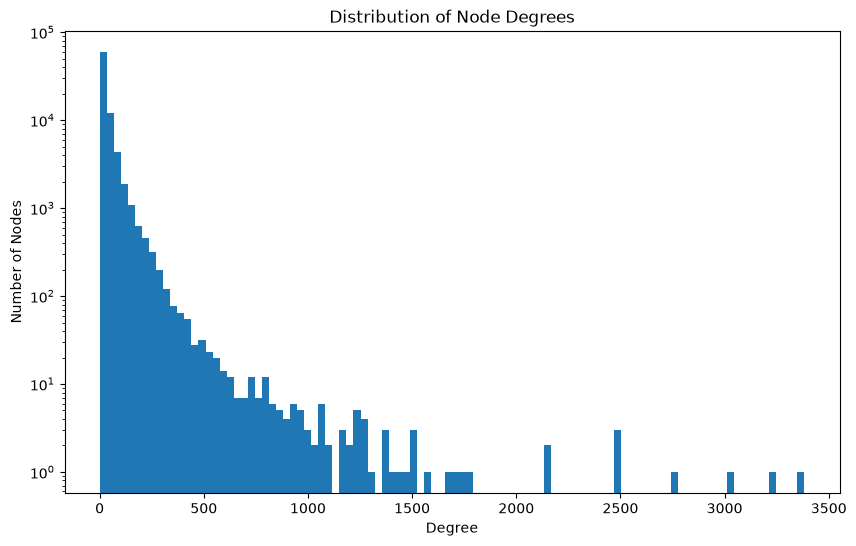

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(degrees, bins=100)
plt.xlabel("Degree")
plt.ylabel("Number of Nodes")
plt.title("Distribution of Node Degrees")
plt.yscale("log")
plt.show()

In [4]:
avg_neighbor_degree = nx.average_neighbor_degree(G)

andeg = np.array(list(avg_neighbor_degree.values()))

print("\nAverage neighbor degree statistics:")
print("Mean:", andeg.mean())
print("Median:", np.median(andeg))
print("Min:", andeg.min())
print("Max:", andeg.max())

degree_val = np.array([G.degree(n) for n in G.nodes()])
neighbor_val = np.array([avg_neighbor_degree[n] for n in G.nodes()])
corr = np.corrcoef(degree_val, neighbor_val)[0, 1]
print("\nCorrelation between node degree and average neighbor degree:", corr)


Average neighbor degree statistics:
Mean: 191.90379624964987
Median: 127.02819138376017
Min: 6.701298701298701
Max: 3239.0

Correlation between node degree and average neighbor degree: -0.0475558992686029


In [5]:
import random

sample_nodes = random.sample(list(G.nodes()), 5000)

clustering_sample = np.array([
    nx.clustering(G, n)
    for n in sample_nodes
])

print("Sampled clustering statistics:")
print("Mean:", clustering_sample.mean())
print("Median:", np.median(clustering_sample))
print("Min:", clustering_sample.min())
print("Max:", clustering_sample.max())

for p in [25, 50, 75, 90, 95, 99]:
    print(f"{p}%:", np.percentile(clustering_sample, p))

Sampled clustering statistics:
Mean: 0.5651897241766258
Median: 0.5777777777777777
Min: 0.0
Max: 1.0
25%: 0.4
50%: 0.5777777777777777
75%: 0.7497332859174964
90%: 1.0
95%: 1.0
99%: 1.0


In [6]:
import numpy as np
import scipy.sparse as sp

# Network adjacency
nodes = list(G.nodes())
node_to_idx = {n: i for i, n in enumerate(nodes)}
N = len(nodes)

rows = []
cols = []

for u, v in G.edges():
    i = node_to_idx[u]
    j = node_to_idx[v]
    rows.extend([i, j])
    cols.extend([j, i])

data = np.ones(len(rows), dtype=np.float32)

A = sp.csr_matrix(
    (data, (rows, cols)),
    shape=(N, N)
)

# Parameters
beta = 0.01
lambda_0 = 1.0
alpha = 0.05
gamma = 0.10
sigma = 0.02
steps = 300

np.random.seed(42)

# Initial state
infected = np.zeros(N, dtype=bool)

# Infect one initial node
initial_node = np.random.randint(N)
infected[initial_node] = True

lam = np.full(N, lambda_0, dtype=np.float32)

# Storage
infection_history = np.zeros((steps + 1, N), dtype=np.bool_)
lambda_history = np.zeros((steps + 1, N), dtype=np.float32)
local_fraction_history = np.zeros((steps + 1, N), dtype=np.float32)

infection_time = np.full(N, np.nan)

infection_history[0] = infected
lambda_history[0] = lam

# Initial local infected fraction
degree = np.asarray(A.sum(axis=1)).ravel()
local_fraction = np.zeros(N, dtype=np.float32)
neighbors_infected = A @ infected.astype(np.float32)
valid = degree > 0
local_fraction[valid] = neighbors_infected[valid] / degree[valid]

local_fraction_history[0] = local_fraction

# Simulation
for t in range(steps):

    # Infection pressure from infected neighbors
    pressure = A @ (lam * infected.astype(np.float32))

    infection_probability = 1.0 - np.exp(-beta * pressure)

    susceptible = ~infected
    new_infections = (
        susceptible &
        (np.random.random(N) < infection_probability)
    )

    # Record infection time
    newly_infected = np.where(new_infections)[0]
    infection_time[newly_infected] = t + 1

    # Update infection state
    infected = infected | new_infections

    # Local infected-neighbor fraction
    neighbors_infected = A @ infected.astype(np.float32)

    local_fraction = np.zeros(N, dtype=np.float32)
    local_fraction[valid] = neighbors_infected[valid] / degree[valid]

    # Infection-rate evolution
    noise = np.random.normal(0, 1, N).astype(np.float32)

    lam = lam + (
        alpha * local_fraction
        - gamma * (lam - lambda_0)
        + sigma * noise
    )

    lam = np.maximum(lam, 0.01)

    # Store
    infection_history[t + 1] = infected
    lambda_history[t + 1] = lam
    local_fraction_history[t + 1] = local_fraction

print("Simulation complete")
print("Nodes:", N)
print("Edges:", G.number_of_edges())
print("Steps:", steps)
print("Final infected:", infected.sum())
print("Final infection fraction:", infected.mean())
print("Nodes never infected:", np.isnan(infection_time).sum())
print("Maximum infection time:", np.nanmax(infection_time))

infection_times = infection_time[~np.isnan(infection_time)]

print("Number infected:", len(infection_times))
print("Minimum infection time:", infection_times.min())
print("Median infection time:", np.median(infection_times))
print("Mean infection time:", infection_times.mean())
print("Maximum infection time:", infection_times.max())

print("\nPercentiles:")
for p in [25, 50, 75, 90, 95, 99]:
    print(f"{p}%:", np.percentile(infection_times, p))

Simulation complete
Nodes: 81306
Edges: 1342296
Steps: 300
Final infected: 81241
Final infection fraction: 0.9992005510048458
Nodes never infected: 66
Maximum infection time: 300.0
Number infected: 81240
Minimum infection time: 2.0
Median infection time: 24.0
Mean infection time: 32.9897341211226
Maximum infection time: 300.0

Percentiles:
25%: 19.0
50%: 24.0
75%: 36.0
90%: 58.0
95%: 82.0
99%: 155.0


In [7]:
import numpy as np
import scipy.sparse as sp

# Parameters from the math
beta = 0.01
lambda_0 = 1.0
alpha = 0.05
gamma = 0.10
sigma = 0.02
steps = 300

np.random.seed(42)

# Initial state
infected = np.zeros(N, dtype=bool)
initial_node = np.random.randint(N)
infected[initial_node] = True

lam = np.full(N, lambda_0, dtype=np.float32)

# Record initial infection time
infection_time = np.full(N, np.nan)
infection_time[initial_node] = 0

# Storage
infection_history = np.zeros((steps + 1, N), dtype=np.bool_)
lambda_history = np.zeros((steps + 1, N), dtype=np.float32)
local_fraction_history = np.zeros((steps + 1, N), dtype=np.float32)

infection_history[0] = infected
lambda_history[0] = lam

# Degree
degree = np.asarray(A.sum(axis=1)).ravel()
valid = degree > 0

# Initial local infected-neighbor fraction
neighbors_infected = A @ infected.astype(np.float32)
local_fraction = np.zeros(N, dtype=np.float32)
local_fraction[valid] = neighbors_infected[valid] / degree[valid]

local_fraction_history[0] = local_fraction

# Simulation
for t in range(steps):

    # Infection pressure from currently infected neighbors
    pressure = A @ (lam * infected.astype(np.float32))

    infection_probability = 1.0 - np.exp(-beta * pressure)

    susceptible = ~infected

    new_infections = (
        susceptible &
        (np.random.random(N) < infection_probability)
    )

    # Record infection time
    newly_infected = np.where(new_infections)[0]
    infection_time[newly_infected] = t + 1

    # Update infection state
    infected = infected | new_infections

    # Local infected-neighbor fraction
    neighbors_infected = A @ infected.astype(np.float32)

    local_fraction = np.zeros(N, dtype=np.float32)
    local_fraction[valid] = neighbors_infected[valid] / degree[valid]

    # IMPORTANT:
    # Only infected nodes evolve their infection rate
    noise = np.random.normal(0, 1, N).astype(np.float32)

    lam_update = (
        alpha * local_fraction
        - gamma * (lam - lambda_0)
        + sigma * noise
    )

    lam[infected] = lam[infected] + lam_update[infected]

    # Susceptible nodes remain at lambda_0
    lam[~infected] = lambda_0

    # Prevent negative rates
    lam = np.maximum(lam, 0.01)

    # Store
    infection_history[t + 1] = infected
    lambda_history[t + 1] = lam
    local_fraction_history[t + 1] = local_fraction

print("Simulation complete")
print("Nodes:", N)
print("Edges:", G.number_of_edges())
print("Steps:", steps)
print("Final infected:", infected.sum())
print("Final infection fraction:", infected.mean())
print("Nodes never infected:", np.isnan(infection_time).sum())
print("Maximum infection time:", np.nanmax(infection_time))

Simulation complete
Nodes: 81306
Edges: 1342296
Steps: 300
Final infected: 81242
Final infection fraction: 0.9992128502201559
Nodes never infected: 64
Maximum infection time: 300.0


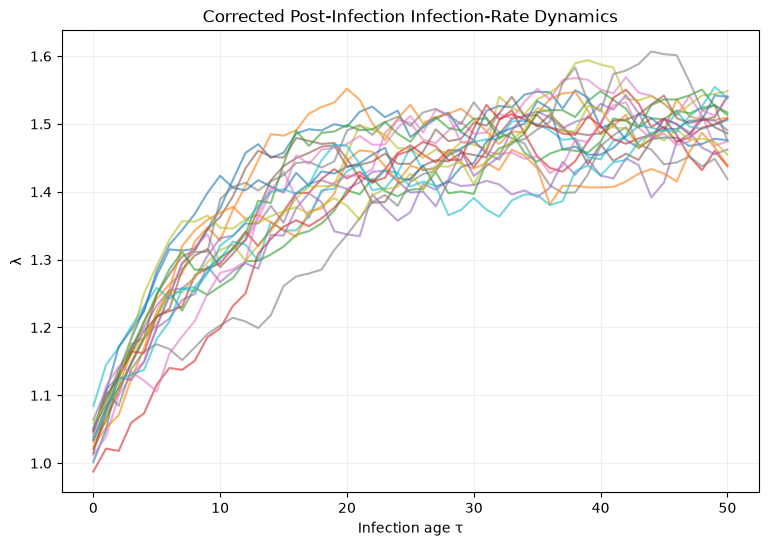

In [8]:
import matplotlib.pyplot as plt

np.random.seed(42)

infected_nodes = np.where(~np.isnan(infection_time))[0]

sample_nodes = np.random.choice(
    infected_nodes,
    size=20,
    replace=False
)

plt.figure(figsize=(9, 6))

for node in sample_nodes:
    t_inf = int(infection_time[node])
    max_age = min(50, steps - t_inf)

    if max_age >= 0:
        ages = np.arange(max_age + 1)
        trajectory = lambda_history[
            t_inf:t_inf + max_age + 1,
            node
        ]

        plt.plot(ages, trajectory, alpha=0.6)

plt.xlabel("Infection age τ")
plt.ylabel("λ")
plt.title("Corrected Post-Infection Infection-Rate Dynamics")
plt.grid(alpha=0.2)
plt.show()

# Comparsion between models to verify
Persistence — predicts the rate will remain at its last observed value.
Linear extrapolation — extends the recent trend.
ARIMA — uses statistical time-series forecasting.
HNN — learns the dynamics and is our main model under investigation.

Comparsions will be done by reviewing their MAE and RMSE over identical held-out forecast windows using multiple random seeds


In [9]:

import numpy as np

# Persistence baseline
OBSERVED_STEPS = 10
FORECAST_STEPS = 10

actual_all = []
predicted_all = []
endpoint_actual = []
endpoint_predicted = []
eligible_nodes = []

infected_nodes = np.where(~np.isnan(infection_time))[0]

for node in infected_nodes:
    t_inf = int(infection_time[node])

    if t_inf + OBSERVED_STEPS + FORECAST_STEPS > steps + 1:
        continue

    trajectory = lambda_history[
        t_inf:t_inf + OBSERVED_STEPS + FORECAST_STEPS,
        node
    ]

    observed = trajectory[:OBSERVED_STEPS]
    actual_future = trajectory[
        OBSERVED_STEPS:OBSERVED_STEPS + FORECAST_STEPS
    ]

    predicted_future = np.full(
        FORECAST_STEPS,
        observed[-1],
        dtype=np.float32
    )

    actual_all.extend(actual_future)
    predicted_all.extend(predicted_future)

    endpoint_actual.append(actual_future[-1])
    endpoint_predicted.append(predicted_future[-1])
    eligible_nodes.append(node)

actual_all = np.asarray(actual_all)
predicted_all = np.asarray(predicted_all)
endpoint_actual = np.asarray(endpoint_actual)
endpoint_predicted = np.asarray(endpoint_predicted)

# Metrics over all forecasted time points
mae = np.mean(np.abs(actual_all - predicted_all))
rmse = np.sqrt(np.mean((actual_all - predicted_all) ** 2))

# Metrics at the final forecast step
endpoint_mae = np.mean(
    np.abs(endpoint_actual - endpoint_predicted)
)
endpoint_rmse = np.sqrt(
    np.mean((endpoint_actual - endpoint_predicted) ** 2)
)

print("PERSISTENCE BASELINE METRICS")
print("Eligible infected nodes:", len(eligible_nodes))
print("Observed steps:", OBSERVED_STEPS)
print("Forecast steps:", FORECAST_STEPS)
print("Forecasted values:", len(actual_all))
print(f"Trajectory MAE: {mae:.6f}")
print(f"Trajectory RMSE: {rmse:.6f}")
print(f"Endpoint MAE: {endpoint_mae:.6f}")
print(f"Endpoint RMSE: {endpoint_rmse:.6f}")


PERSISTENCE BASELINE METRICS
Eligible infected nodes: 81211
Observed steps: 10
Forecast steps: 10
Forecasted values: 812110
Trajectory MAE: 0.080854
Trajectory RMSE: 0.096826
Endpoint MAE: 0.127350
Endpoint RMSE: 0.138550


In [10]:
#Testing linear extrapolation

import numpy as np

OBSERVED_STEPS = 10
FORECAST_STEPS = 10

actual_all = []
predicted_all = []
endpoint_actual = []
endpoint_predicted = []
eligible_nodes = []

infected_nodes = np.where(~np.isnan(infection_time))[0]

for node in infected_nodes:
    t_inf = int(infection_time[node])

    if t_inf + OBSERVED_STEPS + FORECAST_STEPS > steps + 1:
        continue

    trajectory = lambda_history[
        t_inf:t_inf + OBSERVED_STEPS + FORECAST_STEPS,
        node
    ]

    observed = trajectory[:OBSERVED_STEPS]
    actual_future = trajectory[
        OBSERVED_STEPS:OBSERVED_STEPS + FORECAST_STEPS
    ]

    # Estimate the trend from the final two observed values
    slope = observed[-1] - observed[-2]

    predicted_future = np.array([
        observed[-1] + k * slope
        for k in range(1, FORECAST_STEPS + 1)
    ], dtype=np.float32)

    actual_all.extend(actual_future)
    predicted_all.extend(predicted_future)

    endpoint_actual.append(actual_future[-1])
    endpoint_predicted.append(predicted_future[-1])
    eligible_nodes.append(node)

actual_all = np.asarray(actual_all)
predicted_all = np.asarray(predicted_all)
endpoint_actual = np.asarray(endpoint_actual)
endpoint_predicted = np.asarray(endpoint_predicted)

mae = np.mean(np.abs(actual_all - predicted_all))
rmse = np.sqrt(np.mean((actual_all - predicted_all) ** 2))
endpoint_mae = np.mean(np.abs(endpoint_actual - endpoint_predicted))
endpoint_rmse = np.sqrt(
    np.mean((endpoint_actual - endpoint_predicted) ** 2)
)

print("LINEAR EXTRAPOLATION METRICS")
print("Eligible infected nodes:", len(eligible_nodes))
print("Observed steps:", OBSERVED_STEPS)
print("Forecast steps:", FORECAST_STEPS)
print("Forecasted values:", len(actual_all))
print(f"Trajectory MAE: {mae:.6f}")
print(f"Trajectory RMSE: {rmse:.6f}")
print(f"Endpoint MAE: {endpoint_mae:.6f}")
print(f"Endpoint RMSE: {endpoint_rmse:.6f}")


LINEAR EXTRAPOLATION METRICS
Eligible infected nodes: 81211
Observed steps: 10
Forecast steps: 10
Forecasted values: 812110
Trajectory MAE: 0.103110
Trajectory RMSE: 0.144369
Endpoint MAE: 0.184805
Endpoint RMSE: 0.231608


In [11]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:

import numpy as np
from statsmodels.tsa.arima.model import ARIMA
import warnings

warnings.filterwarnings("ignore")

OBSERVED_STEPS = 10
FORECAST_STEPS = 10
MAX_NODES = 500

rng = np.random.default_rng(42)

infected_nodes = np.where(~np.isnan(infection_time))[0]
eligible_nodes = []

for node in infected_nodes:
    t_inf = int(infection_time[node])
    if t_inf + OBSERVED_STEPS + FORECAST_STEPS <= steps + 1:
        eligible_nodes.append(node)

eligible_nodes = np.asarray(eligible_nodes)

# Fixed, reproducible sample
if len(eligible_nodes) > MAX_NODES:
    sampled_nodes = rng.choice(
        eligible_nodes, size=MAX_NODES, replace=False
    )
else:
    sampled_nodes = eligible_nodes

actual_all = []
predicted_all = []
endpoint_actual = []
endpoint_predicted = []
successful_nodes = 0
failed_nodes = 0

for node in sampled_nodes:
    t_inf = int(infection_time[node])

    trajectory = lambda_history[
        t_inf:t_inf + OBSERVED_STEPS + FORECAST_STEPS,
        node
    ]

    observed = np.asarray(
        trajectory[:OBSERVED_STEPS], dtype=float
    )
    actual_future = np.asarray(
        trajectory[OBSERVED_STEPS:], dtype=float
    )

    if (
        len(observed) != OBSERVED_STEPS
        or len(actual_future) != FORECAST_STEPS
        or not np.all(np.isfinite(observed))
        or not np.all(np.isfinite(actual_future))
    ):
        failed_nodes += 1
        continue

    try:
        model = ARIMA(
            observed,
            order=(1, 0, 0),
            trend="c"
        )
        fitted = model.fit()
        predicted_future = np.asarray(
            fitted.forecast(steps=FORECAST_STEPS),
            dtype=float
        )

        if not np.all(np.isfinite(predicted_future)):
            failed_nodes += 1
            continue

        actual_all.extend(actual_future)
        predicted_all.extend(predicted_future)

        endpoint_actual.append(actual_future[-1])
        endpoint_predicted.append(predicted_future[-1])
        successful_nodes += 1

    except Exception:
        failed_nodes += 1

actual_all = np.asarray(actual_all)
predicted_all = np.asarray(predicted_all)
endpoint_actual = np.asarray(endpoint_actual)
endpoint_predicted = np.asarray(endpoint_predicted)

print("ARIMA BASELINE METRICS")
print("Model: ARIMA(1, 0, 0)")
print("Eligible nodes:", len(eligible_nodes))
print("Sampled nodes:", len(sampled_nodes))
print("Successfully forecasted nodes:", successful_nodes)
print("Failed nodes:", failed_nodes)
print("Observed steps:", OBSERVED_STEPS)
print("Forecast steps:", FORECAST_STEPS)

if successful_nodes > 0:
    print("Forecasted values:", len(actual_all))
    print(f"Trajectory MAE: {np.mean(np.abs(actual_all - predicted_all)):.6f}")
    print(f"Trajectory RMSE: {np.sqrt(np.mean((actual_all - predicted_all)**2)):.6f}")
    print(f"Endpoint MAE: {np.mean(np.abs(endpoint_actual - endpoint_predicted)):.6f}")
    print(f"Endpoint RMSE: {np.sqrt(np.mean((endpoint_actual - endpoint_predicted)**2)):.6f}")
else:
    print("No successful forecasts. Check the input data and errors.")


ARIMA BASELINE METRICS
Model: ARIMA(1, 0, 0)
Eligible nodes: 81211
Sampled nodes: 500
Successfully forecasted nodes: 500
Failed nodes: 0
Observed steps: 10
Forecast steps: 10
Forecasted values: 5000
Trajectory MAE: 0.107549
Trajectory RMSE: 0.124646
Endpoint MAE: 0.173101
Endpoint RMSE: 0.181116


In [13]:
#Finally HNN 
OBSERVED_STEPS = 10
FORECAST_STEPS = 10
MAX_NODES = 5000

rng = np.random.default_rng(42)

infected_nodes = np.where(np.isfinite(infection_time))[0]

eligible_nodes = []

for node in infected_nodes:
    t_inf = int(infection_time[node])

    if t_inf + OBSERVED_STEPS + FORECAST_STEPS <= steps + 1:
        eligible_nodes.append(node)

eligible_nodes = np.asarray(eligible_nodes)

if len(eligible_nodes) > MAX_NODES:
    selected_nodes = rng.choice(
        eligible_nodes,
        size=MAX_NODES,
        replace=False
    )
else:
    selected_nodes = eligible_nodes

trajectories = []

for node in selected_nodes:
    t_inf = int(infection_time[node])

    trajectory = lambda_history[
        t_inf:t_inf + OBSERVED_STEPS + FORECAST_STEPS,
        node
    ]

    if (
        len(trajectory) == OBSERVED_STEPS + FORECAST_STEPS
        and np.all(np.isfinite(trajectory))
    ):
        trajectories.append(trajectory)

trajectories = np.asarray(trajectories, dtype=np.float32)

print("Prepared trajectories:", len(trajectories))
print("Trajectory shape:", trajectories.shape)
print("Observed steps:", OBSERVED_STEPS)
print("Forecast steps:", FORECAST_STEPS)



Prepared trajectories: 5000
Trajectory shape: (5000, 20)
Observed steps: 10
Forecast steps: 10


In [14]:

import torch
import torch.nn as nn
import torch.optim as optim

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Use the first 10 points to construct training state transitions.
# q = infection rate; p = change in infection rate.
train_trajectories = trajectories[:, :OBSERVED_STEPS]

q = train_trajectories[:, 1:-1].reshape(-1, 1)
p = (
    train_trajectories[:, 1:-1]
    - train_trajectories[:, :-2]
).reshape(-1, 1)

q_next = train_trajectories[:, 2:].reshape(-1, 1)
p_next = (
    train_trajectories[:, 2:]
    - train_trajectories[:, 1:-1]
).reshape(-1, 1)

# State transitions
states = torch.tensor(
    np.hstack([q, p]), dtype=torch.float32, device=device
)
next_states = torch.tensor(
    np.hstack([q_next, p_next]), dtype=torch.float32, device=device
)

class HamiltonianNN(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, 1)
        )

    def forward(self, state):
        return self.net(state)

model = HamiltonianNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 200
BATCH_SIZE = 1024

dataset = torch.utils.data.TensorDataset(states, next_states)
loader = torch.utils.data.DataLoader(
    dataset, batch_size=BATCH_SIZE, shuffle=True
)

for epoch in range(EPOCHS):
    total_loss = 0.0

    for state_batch, next_batch in loader:
        state_batch = state_batch.detach().requires_grad_(True)

        H = model(state_batch)
        grad_H = torch.autograd.grad(
            H.sum(), state_batch, create_graph=True
        )[0]

        # Hamilton's equations
        q_dot = grad_H[:, 1:2]
        p_dot = -grad_H[:, 0:1]

        # One-step Euler prediction
        predicted = state_batch + torch.cat(
            [q_dot, p_dot], dim=1
        )

        loss = nn.functional.mse_loss(predicted, next_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(state_batch)

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1}/{EPOCHS}, "
            f"Loss: {total_loss / len(dataset):.8f}"
        )

print("Training complete.")


Using device: cpu
Epoch 25/200, Loss: 0.00066057
Epoch 50/200, Loss: 0.00066312
Epoch 75/200, Loss: 0.00066164
Epoch 100/200, Loss: 0.00066529
Epoch 125/200, Loss: 0.00066246
Epoch 150/200, Loss: 0.00066218
Epoch 175/200, Loss: 0.00065980
Epoch 200/200, Loss: 0.00065828
Training complete.


In [15]:

model.eval()

actual_all = []
predicted_all = []
endpoint_actual = []
endpoint_predicted = []

with torch.no_grad():
    for trajectory in trajectories:
        observed = trajectory[:OBSERVED_STEPS]
        actual_future = trajectory[
            OBSERVED_STEPS:OBSERVED_STEPS + FORECAST_STEPS
        ]

        # Initial state: last observed rate and its recent change
        q0 = float(observed[-1])
        p0 = float(observed[-1] - observed[-2])

        state = torch.tensor(
            [[q0, p0]], dtype=torch.float32, device=device
        )

        predictions = []

        for _ in range(FORECAST_STEPS):
            # Enable gradients locally because Hamilton's equations
            # require derivatives of the learned Hamiltonian.
            with torch.enable_grad():
                state = state.detach().requires_grad_(True)
                H = model(state)
                grad_H = torch.autograd.grad(
                    H.sum(), state
                )[0]

            q_dot = grad_H[:, 1:2]
            p_dot = -grad_H[:, 0:1]

            with torch.no_grad():
                state = state + torch.cat(
                    [q_dot, p_dot], dim=1
                )
                predictions.append(state[0, 0].item())

        predicted_future = np.asarray(predictions)
        actual_all.extend(actual_future)
        predicted_all.extend(predicted_future)

        endpoint_actual.append(actual_future[-1])
        endpoint_predicted.append(predicted_future[-1])

actual_all = np.asarray(actual_all)
predicted_all = np.asarray(predicted_all)
endpoint_actual = np.asarray(endpoint_actual)
endpoint_predicted = np.asarray(endpoint_predicted)

print("HNN FORECAST RESULTS")
print("--------------------")
print("Evaluated trajectories:", len(trajectories))
print("Observed steps:", OBSERVED_STEPS)
print("Forecast steps:", FORECAST_STEPS)
print(f"Trajectory MAE: {np.mean(np.abs(actual_all - predicted_all)):.6f}")
print(f"Trajectory RMSE: {np.sqrt(np.mean((actual_all - predicted_all)**2)):.6f}")
print(f"Endpoint MAE: {np.mean(np.abs(endpoint_actual - endpoint_predicted)):.6f}")
print(f"Endpoint RMSE: {np.sqrt(np.mean((endpoint_actual - endpoint_predicted)**2)):.6f}")


HNN FORECAST RESULTS
--------------------
Evaluated trajectories: 5000
Observed steps: 10
Forecast steps: 10
Trajectory MAE: 0.076539
Trajectory RMSE: 0.095962
Endpoint MAE: 0.148391
Endpoint RMSE: 0.158224


In [16]:
#Splitting the trajectories
import numpy as np

# Reproducible 80/20 split by node
rng = np.random.default_rng(42)
indices = rng.permutation(len(trajectories))

split_idx = int(0.8 * len(indices))
train_idx = indices[:split_idx]
test_idx = indices[split_idx:]

train_trajectories = trajectories[train_idx]
test_trajectories = trajectories[test_idx]

print("Training trajectories:", len(train_trajectories))
print("Testing trajectories:", len(test_trajectories))
print("Training shape:", train_trajectories.shape)
print("Testing shape:", test_trajectories.shape)


Training trajectories: 4000
Testing trajectories: 1000
Training shape: (4000, 20)
Testing shape: (1000, 20)


In [17]:

import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Build one-step transitions from TRAINING trajectories only
q_train = train_trajectories[:, 1:-1].reshape(-1, 1)
p_train = (
    train_trajectories[:, 1:-1]
    - train_trajectories[:, :-2]
).reshape(-1, 1)

q_next_train = train_trajectories[:, 2:].reshape(-1, 1)
p_next_train = (
    train_trajectories[:, 2:]
    - train_trajectories[:, 1:-1]
).reshape(-1, 1)

states_train = torch.tensor(
    np.hstack([q_train, p_train]),
    dtype=torch.float32, device=device
)
next_states_train = torch.tensor(
    np.hstack([q_next_train, p_next_train]),
    dtype=torch.float32, device=device
)

train_dataset = torch.utils.data.TensorDataset(
    states_train, next_states_train
)
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=1024, shuffle=True
)

# Fresh model: do not reuse the model trained on all trajectories
model = HamiltonianNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 200

for epoch in range(EPOCHS):
    total_loss = 0.0

    for state_batch, next_batch in train_loader:
        state_batch = state_batch.detach().requires_grad_(True)

        H = model(state_batch)
        grad_H = torch.autograd.grad(
            H.sum(), state_batch, create_graph=True
        )[0]

        q_dot = grad_H[:, 1:2]
        p_dot = -grad_H[:, 0:1]

        predicted = state_batch + torch.cat(
            [q_dot, p_dot], dim=1
        )

        loss = nn.functional.mse_loss(predicted, next_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(state_batch)

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1}/{EPOCHS}, "
            f"Training loss: {total_loss / len(train_dataset):.8f}"
        )

print("Training on training split complete.")


Epoch 25/200, Training loss: 0.00067963
Epoch 50/200, Training loss: 0.00068213
Epoch 75/200, Training loss: 0.00068037
Epoch 100/200, Training loss: 0.00067934
Epoch 125/200, Training loss: 0.00067845
Epoch 150/200, Training loss: 0.00067808
Epoch 175/200, Training loss: 0.00067805
Epoch 200/200, Training loss: 0.00067735
Training on training split complete.


In [18]:
#Evaluate all four models fairly
import numpy as np
import torch
from statsmodels.tsa.arima.model import ARIMA

OBSERVED_STEPS = 10
FORECAST_STEPS = 10

results = {}

# Actual future values: identical for every model
actual = test_trajectories[:, OBSERVED_STEPS:
                           OBSERVED_STEPS + FORECAST_STEPS]

# 1. Persistence
persistence_pred = np.repeat(
    test_trajectories[:, OBSERVED_STEPS - 1:OBSERVED_STEPS],
    FORECAST_STEPS,
    axis=1
)

# 2. Linear extrapolation
last_value = test_trajectories[:, OBSERVED_STEPS - 1]
slope = (
    test_trajectories[:, OBSERVED_STEPS - 1]
    - test_trajectories[:, OBSERVED_STEPS - 2]
)

linear_pred = np.stack([
    last_value + k * slope
    for k in range(1, FORECAST_STEPS + 1)
], axis=1)

# 3. ARIMA(1, 0, 0)
arima_pred = np.zeros_like(actual)

for i, trajectory in enumerate(test_trajectories):
    observed = trajectory[:OBSERVED_STEPS]
    try:
        fitted = ARIMA(observed, order=(1, 0, 0), trend="c").fit()
        arima_pred[i] = fitted.forecast(steps=FORECAST_STEPS)
    except Exception:
        # If a fit fails, use persistence for that trajectory.
        arima_pred[i] = observed[-1]

# 4. HNN: integrate Hamilton's equations forward
model.eval()
hnn_pred = np.zeros_like(actual)

for i, trajectory in enumerate(test_trajectories):
    observed = trajectory[:OBSERVED_STEPS]
    q0 = float(observed[-1])
    p0 = float(observed[-1] - observed[-2])

    state = torch.tensor(
        [[q0, p0]], dtype=torch.float32, device=device
    )
    predictions = []

    for _ in range(FORECAST_STEPS):
        with torch.enable_grad():
            state = state.detach().requires_grad_(True)
            H = model(state)
            grad_H = torch.autograd.grad(H.sum(), state)[0]

        q_dot = grad_H[:, 1:2]
        p_dot = -grad_H[:, 0:1]

        with torch.no_grad():
            state = state + torch.cat([q_dot, p_dot], dim=1)
            predictions.append(state[0, 0].item())

    hnn_pred[i] = predictions

def calculate_metrics(y_true, y_pred):
    endpoint_true = y_true[:, -1]
    endpoint_pred = y_pred[:, -1]

    return {
        "Trajectory MAE": np.mean(np.abs(y_true - y_pred)),
        "Trajectory RMSE": np.sqrt(np.mean((y_true - y_pred) ** 2)),
        "Endpoint MAE": np.mean(np.abs(endpoint_true - endpoint_pred)),
        "Endpoint RMSE": np.sqrt(np.mean((endpoint_true - endpoint_pred) ** 2)),
    }

predictions = {
    "Persistence": persistence_pred,
    "Linear": linear_pred,
    "ARIMA": arima_pred,
    "HNN": hnn_pred
}

for name, pred in predictions.items():
    results[name] = calculate_metrics(actual, pred)

print("HELD-OUT TEST RESULTS")
print("---------------------")
print("Test trajectories:", len(test_trajectories))
print("Forecast steps:", FORECAST_STEPS)

for name, metrics in results.items():
    print(f"\n{name}")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.6f}")


HELD-OUT TEST RESULTS
---------------------
Test trajectories: 1000
Forecast steps: 10

Persistence
Trajectory MAE: 0.082199
Trajectory RMSE: 0.097877
Endpoint MAE: 0.129887
Endpoint RMSE: 0.140404

Linear
Trajectory MAE: 0.099032
Trajectory RMSE: 0.136734
Endpoint MAE: 0.178189
Endpoint RMSE: 0.220464

ARIMA
Trajectory MAE: 0.109431
Trajectory RMSE: 0.126692
Endpoint MAE: 0.176891
Endpoint RMSE: 0.184943

HNN
Trajectory MAE: 0.033029
Trajectory RMSE: 0.042885
Endpoint MAE: 0.044762
Endpoint RMSE: 0.056813


In [19]:

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from statsmodels.tsa.arima.model import ARIMA

OBSERVED_STEPS = 10
FORECAST_STEPS = 10
EPOCHS = 200
BATCH_SIZE = 1024
SEEDS = [7, 21, 42]

def metric_values(actual, predicted):
    return {
        "Trajectory MAE": np.mean(np.abs(actual - predicted)),
        "Trajectory RMSE": np.sqrt(np.mean((actual - predicted) ** 2)),
        "Endpoint MAE": np.mean(np.abs(actual[:, -1] - predicted[:, -1])),
        "Endpoint RMSE": np.sqrt(np.mean((actual[:, -1] - predicted[:, -1]) ** 2))
    }

def evaluate_baselines(train, test):
    actual = test[:, OBSERVED_STEPS:OBSERVED_STEPS + FORECAST_STEPS]
    observed = test[:, :OBSERVED_STEPS]

    persistence = np.repeat(
        observed[:, -1:], FORECAST_STEPS, axis=1
    )

    slope = observed[:, -1] - observed[:, -2]
    linear = np.stack([
        observed[:, -1] + k * slope
        for k in range(1, FORECAST_STEPS + 1)
    ], axis=1)

    arima = np.zeros_like(actual)
    for i, series in enumerate(observed):
        try:
            arima[i] = ARIMA(
                series, order=(1, 0, 0), trend="c"
            ).fit().forecast(steps=FORECAST_STEPS)
        except Exception:
            arima[i] = series[-1]

    return actual, {
        "Persistence": persistence,
        "Linear": linear,
        "ARIMA": arima
    }

def train_hnn(train, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

    q = train[:, 1:-1].reshape(-1, 1)
    p = (train[:, 1:-1] - train[:, :-2]).reshape(-1, 1)
    q_next = train[:, 2:].reshape(-1, 1)
    p_next = (train[:, 2:] - train[:, 1:-1]).reshape(-1, 1)

    states = torch.tensor(
        np.hstack([q, p]), dtype=torch.float32, device=device
    )
    next_states = torch.tensor(
        np.hstack([q_next, p_next]), dtype=torch.float32, device=device
    )

    dataset = torch.utils.data.TensorDataset(states, next_states)
    loader = torch.utils.data.DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True
    )

    model = HamiltonianNN().to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(EPOCHS):
        for state_batch, next_batch in loader:
            state_batch = state_batch.detach().requires_grad_(True)
            H = model(state_batch)
            grad_H = torch.autograd.grad(
                H.sum(), state_batch, create_graph=True
            )[0]

            derivative = torch.cat(
                [grad_H[:, 1:2], -grad_H[:, 0:1]], dim=1
            )
            predicted = state_batch + derivative
            loss = nn.functional.mse_loss(predicted, next_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    return model

def forecast_hnn(model, test):
    predictions = np.zeros(
        (len(test), FORECAST_STEPS), dtype=np.float32
    )
    model.eval()

    for i, series in enumerate(test[:, :OBSERVED_STEPS]):
        state = torch.tensor(
            [[float(series[-1]), float(series[-1] - series[-2])]],
            dtype=torch.float32, device=device
        )
        for k in range(FORECAST_STEPS):
            with torch.enable_grad():
                state = state.detach().requires_grad_(True)
                H = model(state)
                grad_H = torch.autograd.grad(H.sum(), state)[0]

            derivative = torch.cat(
                [grad_H[:, 1:2], -grad_H[:, 0:1]], dim=1
            )
            with torch.no_grad():
                state = state + derivative
                predictions[i, k] = state[0, 0].item()

    return predictions

all_results = []

for seed in SEEDS:
    print(f"\nRunning seed {seed}...")

    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(trajectories))
    split = int(0.8 * len(indices))
    train = trajectories[indices[:split]]
    test = trajectories[indices[split:]]

    actual, baseline_predictions = evaluate_baselines(train, test)
    model_seed = train_hnn(train, seed)
    baseline_predictions["HNN"] = forecast_hnn(model_seed, test)

    for model_name, prediction in baseline_predictions.items():
        metrics = metric_values(actual, prediction)
        row = {"Seed": seed, "Model": model_name, **metrics}
        all_results.append(row)
        print(model_name, {k: round(v, 6) for k, v in metrics.items()})

print("\nMulti-seed runs complete. Results stored in all_results.")



Running seed 7...
Persistence {'Trajectory MAE': np.float32(0.081329), 'Trajectory RMSE': np.float32(0.097255), 'Endpoint MAE': np.float32(0.128438), 'Endpoint RMSE': np.float32(0.13936)}
Linear {'Trajectory MAE': np.float32(0.098803), 'Trajectory RMSE': np.float32(0.139341), 'Endpoint MAE': np.float32(0.177087), 'Endpoint RMSE': np.float32(0.22397)}
ARIMA {'Trajectory MAE': np.float32(0.108455), 'Trajectory RMSE': np.float32(0.125599), 'Endpoint MAE': np.float32(0.175453), 'Endpoint RMSE': np.float32(0.183311)}
HNN {'Trajectory MAE': np.float32(0.032776), 'Trajectory RMSE': np.float32(0.042167), 'Endpoint MAE': np.float32(0.043853), 'Endpoint RMSE': np.float32(0.054864)}

Running seed 21...
Persistence {'Trajectory MAE': np.float32(0.083185), 'Trajectory RMSE': np.float32(0.099036), 'Endpoint MAE': np.float32(0.130979), 'Endpoint RMSE': np.float32(0.141648)}
Linear {'Trajectory MAE': np.float32(0.104584), 'Trajectory RMSE': np.float32(0.146312), 'Endpoint MAE': np.float32(0.187018), 

In [20]:

import numpy as np

OBSERVED_STEPS = 10
FORECAST_STEPS = 10

# Mean trajectory calculated from TRAINING nodes only
mean_training_trajectory = np.mean(
    train_trajectories, axis=0
)

# Use the average training trajectory's future as every prediction
mean_future = mean_training_trajectory[
    OBSERVED_STEPS:OBSERVED_STEPS + FORECAST_STEPS
]

actual = test_trajectories[
    :, OBSERVED_STEPS:OBSERVED_STEPS + FORECAST_STEPS
]

mean_pred = np.tile(
    mean_future, (len(test_trajectories), 1)
)

def calculate_metrics(y_true, y_pred):
    return {
        "Trajectory MAE": np.mean(np.abs(y_true - y_pred)),
        "Trajectory RMSE": np.sqrt(np.mean((y_true - y_pred) ** 2)),
        "Endpoint MAE": np.mean(
            np.abs(y_true[:, -1] - y_pred[:, -1])
        ),
        "Endpoint RMSE": np.sqrt(
            np.mean((y_true[:, -1] - y_pred[:, -1]) ** 2)
        )
    }

metrics = calculate_metrics(actual, mean_pred)

print("MEAN-TRAJECTORY BASELINE")
print("------------------------")
print("Test trajectories:", len(test_trajectories))

for name, value in metrics.items():
    print(f"{name}: {value:.6f}")


MEAN-TRAJECTORY BASELINE
------------------------
Test trajectories: 1000
Trajectory MAE: 0.049386
Trajectory RMSE: 0.065323
Endpoint MAE: 0.047287
Endpoint RMSE: 0.063345


In [21]:
#Constructing an MLP to see if it can forecast as well as HNN

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OBSERVED_STEPS = 10
FORECAST_STEPS = 10

# Input: first 10 values; target: next 10 values
X_train = train_trajectories[:, :OBSERVED_STEPS]
y_train = train_trajectories[
    :, OBSERVED_STEPS:OBSERVED_STEPS + FORECAST_STEPS
]

X_test = test_trajectories[:, :OBSERVED_STEPS]
y_test = test_trajectories[
    :, OBSERVED_STEPS:OBSERVED_STEPS + FORECAST_STEPS
]

X_train_t = torch.tensor(X_train, dtype=torch.float32, device=device)
y_train_t = torch.tensor(y_train, dtype=torch.float32, device=device)

class MLPForecaster(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(OBSERVED_STEPS, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, FORECAST_STEPS)
        )

    def forward(self, x):
        return self.net(x)

mlp = MLPForecaster().to(device)
optimizer = optim.Adam(mlp.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

dataset = torch.utils.data.TensorDataset(X_train_t, y_train_t)
loader = torch.utils.data.DataLoader(
    dataset, batch_size=256, shuffle=True
)

EPOCHS = 200

for epoch in range(EPOCHS):
    mlp.train()
    total_loss = 0.0

    for xb, yb in loader:
        prediction = mlp(xb)
        loss = loss_fn(prediction, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1}/{EPOCHS}, "
            f"Training loss: {total_loss / len(dataset):.8f}"
        )

print("MLP training complete.")


Epoch 25/200, Training loss: 0.00220070
Epoch 50/200, Training loss: 0.00219112
Epoch 75/200, Training loss: 0.00212854
Epoch 100/200, Training loss: 0.00208076
Epoch 125/200, Training loss: 0.00202692
Epoch 150/200, Training loss: 0.00195507
Epoch 175/200, Training loss: 0.00188833
Epoch 200/200, Training loss: 0.00182387
MLP training complete.


In [22]:

mlp.eval()

with torch.no_grad():
    mlp_pred = mlp(
        torch.tensor(X_test, dtype=torch.float32, device=device)
    ).cpu().numpy()

actual = y_test

def calculate_metrics(y_true, y_pred):
    return {
        "Trajectory MAE": np.mean(np.abs(y_true - y_pred)),
        "Trajectory RMSE": np.sqrt(np.mean((y_true - y_pred) ** 2)),
        "Endpoint MAE": np.mean(
            np.abs(y_true[:, -1] - y_pred[:, -1])
        ),
        "Endpoint RMSE": np.sqrt(
            np.mean((y_true[:, -1] - y_pred[:, -1]) ** 2)
        )
    }

mlp_metrics = calculate_metrics(actual, mlp_pred)

print("MLP FORECAST RESULTS")
print("--------------------")
print("Test trajectories:", len(actual))

for metric, value in mlp_metrics.items():
    print(f"{metric}: {value:.6f}")


MLP FORECAST RESULTS
--------------------
Test trajectories: 1000
Trajectory MAE: 0.034379
Trajectory RMSE: 0.044120
Endpoint MAE: 0.040093
Endpoint RMSE: 0.050936


In [23]:

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

def evaluate_mlp_seed(seed, trajectories):
    np.random.seed(seed)
    torch.manual_seed(seed)

    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(trajectories))
    split = int(0.8 * len(indices))

    train = trajectories[indices[:split]]
    test = trajectories[indices[split:]]

    X_train = torch.tensor(train[:, :10], dtype=torch.float32, device=device)
    y_train = torch.tensor(train[:, 10:], dtype=torch.float32, device=device)
    X_test = torch.tensor(test[:, :10], dtype=torch.float32, device=device)

    model = MLPForecaster().to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()

    dataset = torch.utils.data.TensorDataset(X_train, y_train)
    loader = torch.utils.data.DataLoader(
        dataset, batch_size=256, shuffle=True
    )

    for epoch in range(200):
        model.train()
        for xb, yb in loader:
            prediction = model(xb)
            loss = loss_fn(prediction, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        predictions = model(X_test).cpu().numpy()

    actual = test[:, 10:]

    return {
        "Seed": seed,
        "Trajectory MAE": np.mean(np.abs(actual - predictions)),
        "Trajectory RMSE": np.sqrt(np.mean((actual - predictions) ** 2)),
        "Endpoint MAE": np.mean(
            np.abs(actual[:, -1] - predictions[:, -1])
        ),
        "Endpoint RMSE": np.sqrt(
            np.mean((actual[:, -1] - predictions[:, -1]) ** 2)
        )
    }

mlp_results = [
    evaluate_mlp_seed(seed, trajectories)
    for seed in [7, 21, 42]
]

for result in mlp_results:
    print(result)

print("\nMEAN METRICS ACROSS SEEDS")
for metric in [
    "Trajectory MAE", "Trajectory RMSE",
    "Endpoint MAE", "Endpoint RMSE"
]:
    print(
        f"{metric}: "
        f"{np.mean([r[metric] for r in mlp_results]):.6f}"
    )


{'Seed': 7, 'Trajectory MAE': np.float32(0.032350715), 'Trajectory RMSE': np.float32(0.041378234), 'Endpoint MAE': np.float32(0.039317317), 'Endpoint RMSE': np.float32(0.04944731)}
{'Seed': 21, 'Trajectory MAE': np.float32(0.03248188), 'Trajectory RMSE': np.float32(0.041368645), 'Endpoint MAE': np.float32(0.03985218), 'Endpoint RMSE': np.float32(0.05038975)}
{'Seed': 42, 'Trajectory MAE': np.float32(0.034379076), 'Trajectory RMSE': np.float32(0.04412035), 'Endpoint MAE': np.float32(0.040093366), 'Endpoint RMSE': np.float32(0.050936446)}

MEAN METRICS ACROSS SEEDS
Trajectory MAE: 0.033071
Trajectory RMSE: 0.042289
Endpoint MAE: 0.039754
Endpoint RMSE: 0.050258


In [24]:
def evaluate_mean_baseline(seed, trajectories):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(trajectories))
    split = int(0.8 * len(indices))

    train = trajectories[indices[:split]]
    test = trajectories[indices[split:]]

    # Learn the average trajectory from training data only
    mean_trajectory = np.mean(train, axis=0)

    # Use its future 10 steps for every test trajectory
    predictions = np.tile(mean_trajectory[10:20], (len(test), 1))
    actual = test[:, 10:20]

    return {
        "Seed": seed,
        "Trajectory MAE": np.mean(np.abs(actual - predictions)),
        "Trajectory RMSE": np.sqrt(np.mean((actual - predictions) ** 2)),
        "Endpoint MAE": np.mean(
            np.abs(actual[:, -1] - predictions[:, -1])
        ),
        "Endpoint RMSE": np.sqrt(
            np.mean((actual[:, -1] - predictions[:, -1]) ** 2)
        )
    }

mean_results = [
    evaluate_mean_baseline(seed, trajectories)
    for seed in [7, 21, 42]
]

for result in mean_results:
    print(result)

print("\nMEAN METRICS ACROSS SEEDS")
for metric in [
    "Trajectory MAE", "Trajectory RMSE",
    "Endpoint MAE", "Endpoint RMSE"
]:
    average = np.mean([r[metric] for r in mean_results])
    print(f"{metric}: {average:.6f}")


{'Seed': 7, 'Trajectory MAE': np.float32(0.047909345), 'Trajectory RMSE': np.float32(0.063210666), 'Endpoint MAE': np.float32(0.045175225), 'Endpoint RMSE': np.float32(0.060289998)}
{'Seed': 21, 'Trajectory MAE': np.float32(0.04819153), 'Trajectory RMSE': np.float32(0.06269883), 'Endpoint MAE': np.float32(0.04649867), 'Endpoint RMSE': np.float32(0.060457997)}
{'Seed': 42, 'Trajectory MAE': np.float32(0.04938626), 'Trajectory RMSE': np.float32(0.06532329), 'Endpoint MAE': np.float32(0.047287118), 'Endpoint RMSE': np.float32(0.06334455)}

MEAN METRICS ACROSS SEEDS
Trajectory MAE: 0.048496
Trajectory RMSE: 0.063744
Endpoint MAE: 0.046320
Endpoint RMSE: 0.061364


In [26]:
print("=== TRAIN / TEST DATA ===")

for name in ["train_trajectories", "test_trajectories"]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"{name}: not found")

print("\n=== HNN-RELATED VARIABLES ===")

for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "hamilton", "hnn", "optimizer", "train_q", "train_p"
    ]):
        value = globals()[name]
        if hasattr(value, "shape"):
            print(f"{name}: shape={value.shape}")
        else:
            print(f"{name}: {type(value).__name__}")

print("\n=== MODEL OBJECTS ===")

for name in ["hnn", "model", "mlp"]:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "parameters"):
            print(f"{name}: {type(value).__name__}")
            print(value)

=== TRAIN / TEST DATA ===
train_trajectories: shape=(4000, 20), dtype=float32
test_trajectories: shape=(1000, 20), dtype=float32

=== HNN-RELATED VARIABLES ===
HamiltonianNN: type
forecast_hnn: function
hnn_pred: shape=(1000, 10)
optimizer: Adam
train_hnn: function

=== MODEL OBJECTS ===
model: HamiltonianNN
HamiltonianNN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
mlp: MLPForecaster
MLPForecaster(
  (net): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [27]:
import inspect
import dis

for name in ["train_hnn", "forecast_hnn"]:
    fn = globals()[name]
    print(f"\n{'='*20} {name} {'='*20}")
    try:
        print(inspect.getsource(fn))
    except (OSError, TypeError):
        print("Source unavailable; showing bytecode:")
        dis.dis(fn)


==================== train_hnn ====================
def train_hnn(train, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

    q = train[:, 1:-1].reshape(-1, 1)
    p = (train[:, 1:-1] - train[:, :-2]).reshape(-1, 1)
    q_next = train[:, 2:].reshape(-1, 1)
    p_next = (train[:, 2:] - train[:, 1:-1]).reshape(-1, 1)

    states = torch.tensor(
        np.hstack([q, p]), dtype=torch.float32, device=device
    )
    next_states = torch.tensor(
        np.hstack([q_next, p_next]), dtype=torch.float32, device=device
    )

    dataset = torch.utils.data.TensorDataset(states, next_states)
    loader = torch.utils.data.DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True
    )

    model = HamiltonianNN().to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(EPOCHS):
        for state_batch, next_batch in loader:
            state_batch = state_batch.detach().requires_grad_(True)
            H = model(state_batch)
            grad_

In [28]:
import numpy as np
import torch

# 1. Forecast validity
print("=== HNN FORECAST DIAGNOSTICS ===")
print("Prediction shape:", hnn_pred.shape)
print("Non-finite predictions:", np.sum(~np.isfinite(hnn_pred)))
print("Negative predictions:", np.sum(hnn_pred < 0))
print("Minimum predicted rate:", np.nanmin(hnn_pred))
print("Maximum predicted rate:", np.nanmax(hnn_pred))

# 2. Compare observed and forecast ranges
observed = test_trajectories[:, :OBSERVED_STEPS]
actual_future = test_trajectories[:, OBSERVED_STEPS:]

print("\n=== RATE RANGES ===")
print("Observed: min =", observed.min(), "max =", observed.max())
print("Actual future: min =", actual_future.min(),
      "max =", actual_future.max())
print("Predicted future: min =", np.nanmin(hnn_pred),
      "max =", np.nanmax(hnn_pred))

# 3. Check whether forecasts deteriorate over the horizon
errors = np.abs(hnn_pred - actual_future)
print("\n=== MAE BY FORECAST STEP ===")
for k, value in enumerate(errors.mean(axis=0), start=1):
    print(f"Step {k:2d}: MAE = {value:.6f}")

# 4. Check how much of the test data is near-constant
changes = np.abs(np.diff(observed, axis=1))
print("\n=== OBSERVED TRAJECTORY VARIATION ===")
print("Median within-window absolute change:",
      np.median(changes))
print("Fraction with all observed changes < 1e-6:",
      np.mean(np.all(changes < 1e-6, axis=1)))

=== HNN FORECAST DIAGNOSTICS ===
Prediction shape: (1000, 10)
Non-finite predictions: 0
Negative predictions: 0
Minimum predicted rate: 1.0416051
Maximum predicted rate: 1.5700542

=== RATE RANGES ===
Observed: min = 0.9402958 max = 1.4573694
Actual future: min = 1.0096418 max = 1.5759037
Predicted future: min = 1.0416051 max = 1.5700542

=== MAE BY FORECAST STEP ===
Step  1: MAE = 0.016443
Step  2: MAE = 0.022727
Step  3: MAE = 0.027287
Step  4: MAE = 0.030795
Step  5: MAE = 0.032999
Step  6: MAE = 0.035540
Step  7: MAE = 0.037112
Step  8: MAE = 0.039808
Step  9: MAE = 0.042819
Step 10: MAE = 0.044762

=== OBSERVED TRAJECTORY VARIATION ===
Median within-window absolute change: 0.028153777
Fraction with all observed changes < 1e-6: 0.0


In [29]:
import numpy as np
import torch

model.eval()

# Construct transitions from the held-out observed windows.
obs = test_trajectories[:, :OBSERVED_STEPS]

q = obs[:, 1:-1].reshape(-1, 1)
p = (obs[:, 1:-1] - obs[:, :-2]).reshape(-1, 1)

q_next = obs[:, 2:].reshape(-1, 1)
p_next = (obs[:, 2:] - obs[:, 1:-1]).reshape(-1, 1)

states = torch.tensor(
    np.hstack([q, p]), dtype=torch.float32, device=device
)
targets = torch.tensor(
    np.hstack([q_next, p_next]), dtype=torch.float32, device=device
)

states.requires_grad_(True)
H = model(states)
grad_H = torch.autograd.grad(H.sum(), states)[0]

derivative = torch.cat(
    [grad_H[:, 1:2], -grad_H[:, 0:1]], dim=1
)
predicted = states + derivative

with torch.no_grad():
    errors = predicted - targets
    print("Held-out observed-window transitions:", len(targets))
    print("One-step q MAE:", errors[:, 0].abs().mean().item())
    print("One-step q RMSE:",
          torch.sqrt((errors[:, 0] ** 2).mean()).item())
    print("One-step p MAE:", errors[:, 1].abs().mean().item())
    print("One-step p RMSE:",
          torch.sqrt((errors[:, 1] ** 2).mean()).item())

Held-out observed-window transitions: 8000
One-step q MAE: 0.01733933761715889
One-step q RMSE: 0.021666912361979485
One-step p MAE: 0.024188419803977013
One-step p RMSE: 0.030357036739587784


In [30]:

obs = test_trajectories[:, :OBSERVED_STEPS]

# Same transition positions used in the HNN diagnostic.
actual_next = obs[:, 2:]
persistence_next = obs[:, 1:-1]

mae_persistence = np.mean(np.abs(actual_next - persistence_next))
rmse_persistence = np.sqrt(np.mean((actual_next - persistence_next) ** 2))

print("=== ONE-STEP BASELINE COMPARISON ===")
print(f"HNN q MAE:        {0.01733933761715889:.6f}")
print(f"Persistence MAE:  {mae_persistence:.6f}")
print(f"HNN q RMSE:       {0.021666912361979485:.6f}")
print(f"Persistence RMSE: {rmse_persistence:.6f}")
print(f"MAE improvement:  "
      f"{100 * (1 - 0.01733933761715889 / mae_persistence):.2f}%")
print(f"RMSE improvement: "
      f"{100 * (1 - 0.021666912361979485 / rmse_persistence):.2f}%")

=== ONE-STEP BASELINE COMPARISON ===
HNN q MAE:        0.017339
Persistence MAE:  0.028996
HNN q RMSE:       0.021667
Persistence RMSE: 0.034383
MAE improvement:  40.20%
RMSE improvement: 36.98%


In [32]:
print("=== SEED-RELATED VARIABLES ===")

for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "seed", "result", "metric", "mae", "rmse", "hnn"
    ]):
        value = globals()[name]

        if isinstance(value, (list, tuple, dict)):
            print(f"{name}: {type(value).__name__}, length={len(value)}")
        elif hasattr(value, "shape"):
            print(f"{name}: shape={value.shape}")
        elif isinstance(value, (int, float, str)):
            print(f"{name}: {value}")
            
print("SEEDS:", SEEDS)

print("\n=== all_results: first 4 entries ===")
for i, item in enumerate(all_results[:4]):
    print(f"\nEntry {i}:")
    print(item)

print("\n=== mean_results ===")
for item in mean_results:
    print(item)

print("\n=== mlp_results ===")
for item in mlp_results:
    print(item)

=== SEED-RELATED VARIABLES ===
SEEDS: list, length=3
all_results: list, length=12
endpoint_mae: shape=()
endpoint_rmse: shape=()
hnn_pred: shape=(1000, 10)
mae: shape=()
mae_persistence: shape=()
mean_results: list, length=3
metric: Endpoint RMSE
metrics: dict, length=4
mlp_metrics: dict, length=4
mlp_results: list, length=3
result: dict, length=5
results: dict, length=4
rmse: shape=()
rmse_persistence: shape=()
seed: 42
SEEDS: [7, 21, 42]

=== all_results: first 4 entries ===

Entry 0:
{'Seed': 7, 'Model': 'Persistence', 'Trajectory MAE': np.float32(0.08132866), 'Trajectory RMSE': np.float32(0.0972552), 'Endpoint MAE': np.float32(0.12843783), 'Endpoint RMSE': np.float32(0.13935955)}

Entry 1:
{'Seed': 7, 'Model': 'Linear', 'Trajectory MAE': np.float32(0.09880265), 'Trajectory RMSE': np.float32(0.13934053), 'Endpoint MAE': np.float32(0.17708676), 'Endpoint RMSE': np.float32(0.22397001)}

Entry 2:
{'Seed': 7, 'Model': 'ARIMA', 'Trajectory MAE': np.float32(0.10845464), 'Trajectory RMSE':

In [33]:
import pandas as pd

df_results = pd.DataFrame(all_results)

metric_cols = [
    "Trajectory MAE",
    "Trajectory RMSE",
    "Endpoint MAE",
    "Endpoint RMSE"
]

print("=== RESULTS BY SEED ===")
print(
    df_results.sort_values(["Seed", "Model"])
    .to_string(index=False, float_format=lambda x: f"{x:.6f}")
)

print("\n=== MEAN ± STANDARD DEVIATION ACROSS SEEDS ===")
summary = (
    df_results.groupby("Model")[metric_cols]
    .agg(["mean", "std"])
)

print(summary.round(6).to_string())

=== RESULTS BY SEED ===
 Seed       Model  Trajectory MAE  Trajectory RMSE  Endpoint MAE  Endpoint RMSE
    7       ARIMA        0.108455         0.125599      0.175453       0.183311
    7         HNN        0.032776         0.042167      0.043853       0.054864
    7      Linear        0.098803         0.139341      0.177087       0.223970
    7 Persistence        0.081329         0.097255      0.128438       0.139360
   21       ARIMA        0.110801         0.127897      0.178330       0.186155
   21         HNN        0.032080         0.041432      0.043064       0.054542
   21      Linear        0.104584         0.146312      0.187018       0.235028
   21 Persistence        0.083185         0.099036      0.130979       0.141648
   42       ARIMA        0.109431         0.126692      0.176891       0.184943
   42         HNN        0.033029         0.042885      0.044762       0.056813
   42      Linear        0.099032         0.136734      0.178189       0.220464
   42 Persistenc

In [35]:
import pandas as pd

print("Models currently in all_results:")
print(sorted(set(row["Model"] for row in all_results)))

print("=== MLP RESULTS: first entry ===")
print(mlp_results[0])

print("\n=== MEAN-TRAJECTORY RESULTS: first entry ===")
print(mean_results[0])

print("\n=== ALL_RESULTS: first entry ===")
print(all_results[0])

Models currently in all_results:
['ARIMA', 'HNN', 'Linear', 'Persistence']
=== MLP RESULTS: first entry ===
{'Seed': 7, 'Trajectory MAE': np.float32(0.032350715), 'Trajectory RMSE': np.float32(0.041378234), 'Endpoint MAE': np.float32(0.039317317), 'Endpoint RMSE': np.float32(0.04944731)}

=== MEAN-TRAJECTORY RESULTS: first entry ===
{'Seed': 7, 'Trajectory MAE': np.float32(0.047909345), 'Trajectory RMSE': np.float32(0.063210666), 'Endpoint MAE': np.float32(0.045175225), 'Endpoint RMSE': np.float32(0.060289998)}

=== ALL_RESULTS: first entry ===
{'Seed': 7, 'Model': 'Persistence', 'Trajectory MAE': np.float32(0.08132866), 'Trajectory RMSE': np.float32(0.0972552), 'Endpoint MAE': np.float32(0.12843783), 'Endpoint RMSE': np.float32(0.13935955)}


In [36]:
import pandas as pd

# Copy the existing results so we don't modify the originals
combined_results = list(all_results)

# Add model labels to the other two result collections
for row in mlp_results:
    combined_results.append({**row, "Model": "MLP"})

for row in mean_results:
    combined_results.append({**row, "Model": "Mean trajectory"})

df_all = pd.DataFrame(combined_results)

metric_cols = [
    "Trajectory MAE",
    "Trajectory RMSE",
    "Endpoint MAE",
    "Endpoint RMSE"
]

print("=== RESULTS BY SEED AND MODEL ===")
print(
    df_all.sort_values(["Seed", "Model"]).to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n=== MEAN ± STANDARD DEVIATION ACROSS SEEDS ===")
summary_all = df_all.groupby("Model")[metric_cols].agg(["mean", "std"])
print(summary_all.round(6).to_string())

=== RESULTS BY SEED AND MODEL ===
 Seed           Model  Trajectory MAE  Trajectory RMSE  Endpoint MAE  Endpoint RMSE
    7           ARIMA        0.108455         0.125599      0.175453       0.183311
    7             HNN        0.032776         0.042167      0.043853       0.054864
    7          Linear        0.098803         0.139341      0.177087       0.223970
    7             MLP        0.032351         0.041378      0.039317       0.049447
    7 Mean trajectory        0.047909         0.063211      0.045175       0.060290
    7     Persistence        0.081329         0.097255      0.128438       0.139360
   21           ARIMA        0.110801         0.127897      0.178330       0.186155
   21             HNN        0.032080         0.041432      0.043064       0.054542
   21          Linear        0.104584         0.146312      0.187018       0.235028
   21             MLP        0.032482         0.041369      0.039852       0.050390
   21 Mean trajectory        0.048192     

In [37]:
[name for name in globals()
 if "arima" in name.lower() and callable(globals()[name])]

['ARIMA']

In [39]:
import inspect

print("=== Functions related to ARIMA ===")

for name, obj in globals().copy().items():
    if callable(obj) and "arima" in name.lower():
        try:
            print(f"\n--- {name} ---")
            print("Defined in:", inspect.getsourcefile(obj))
            print("Function name:", getattr(obj, "__name__", type(obj).__name__))
        except Exception as e:
            print(f"{name}: could not inspect ({e})")

=== Functions related to ARIMA ===

--- ARIMA ---
Defined in: c:\Users\Joshua\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\arima\model.py
Function name: ARIMA


In [40]:
import inspect

keywords = ["forecast", "evaluate", "predict", "arima"]

for name, obj in globals().copy().items():
    if callable(obj) and inspect.isfunction(obj):
        try:
            source = inspect.getsource(obj)
            if any(word in (name + source).lower() for word in keywords):
                print(f"\n{'=' * 60}")
                print(f"FUNCTION: {name}")
                print(source[:5000])
        except (OSError, TypeError):
            pass


FUNCTION: value
def train_hnn(train, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

    q = train[:, 1:-1].reshape(-1, 1)
    p = (train[:, 1:-1] - train[:, :-2]).reshape(-1, 1)
    q_next = train[:, 2:].reshape(-1, 1)
    p_next = (train[:, 2:] - train[:, 1:-1]).reshape(-1, 1)

    states = torch.tensor(
        np.hstack([q, p]), dtype=torch.float32, device=device
    )
    next_states = torch.tensor(
        np.hstack([q_next, p_next]), dtype=torch.float32, device=device
    )

    dataset = torch.utils.data.TensorDataset(states, next_states)
    loader = torch.utils.data.DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True
    )

    model = HamiltonianNN().to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(EPOCHS):
        for state_batch, next_batch in loader:
            state_batch = state_batch.detach().requires_grad_(True)
            H = model(state_batch)
            grad_H = torch.autograd.grad(
           

In [41]:
import numpy as np
import warnings
from statsmodels.tsa.arima.model import ARIMA

def evaluate_baselines_audited(train, test):
    actual = test[:, OBSERVED_STEPS:OBSERVED_STEPS + FORECAST_STEPS]
    observed = test[:, :OBSERVED_STEPS]

    persistence = np.repeat(
        observed[:, -1:], FORECAST_STEPS, axis=1
    )

    slope = observed[:, -1] - observed[:, -2]
    linear = np.stack([
        observed[:, -1] + k * slope
        for k in range(1, FORECAST_STEPS + 1)
    ], axis=1)

    arima = np.full(actual.shape, np.nan, dtype=float)
    failures = []

    for i, series in enumerate(observed):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fitted = ARIMA(
                    series, order=(1, 0, 0), trend="c"
                ).fit()

                forecast = np.asarray(
                    fitted.forecast(steps=FORECAST_STEPS)
                ).reshape(-1)

            if len(forecast) != FORECAST_STEPS or not np.all(
                np.isfinite(forecast)
            ):
                raise ValueError("Forecast has invalid values or length")

            arima[i] = forecast

        except Exception as e:
            failures.append({
                "trajectory_index": i,
                "error": repr(e)
            })

    print(f"Total test trajectories: {len(observed)}")
    print(f"Successful ARIMA forecasts: {len(observed) - len(failures)}")
    print(f"Failed ARIMA forecasts: {len(failures)}")
    print(f"Failure rate: {len(failures) / len(observed):.2%}")

    if failures:
        print("\nFirst five failures:")
        for failure in failures[:5]:
            print(failure)

    return actual, {
        "Persistence": persistence,
        "Linear": linear,
        "ARIMA": arima
    }, failures

In [42]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(trajectories))
split = int(0.8 * len(indices))

train_42 = trajectories[indices[:split]]
test_42 = trajectories[indices[split:]]

actual_42, baseline_preds_42, arima_failures_42 = (
    evaluate_baselines_audited(train_42, test_42)
)

Total test trajectories: 1000
Successful ARIMA forecasts: 1000
Failed ARIMA forecasts: 0
Failure rate: 0.00%


In [43]:
audit_results = []

for seed in [7, 21, 42]:
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(trajectories))
    split = int(0.8 * len(indices))

    train = trajectories[indices[:split]]
    test = trajectories[indices[split:]]

    print(f"\n{'=' * 40}\nSEED {seed}\n{'=' * 40}")

    _, _, failures = evaluate_baselines_audited(train, test)

    audit_results.append({
        "Seed": seed,
        "Test trajectories": len(test),
        "Failures": len(failures),
        "Failure rate": len(failures) / len(test)
    })

import pandas as pd
print("\n=== ARIMA AUDIT SUMMARY ===")
print(pd.DataFrame(audit_results).to_string(index=False))


SEED 7
Total test trajectories: 1000
Successful ARIMA forecasts: 1000
Failed ARIMA forecasts: 0
Failure rate: 0.00%

SEED 21
Total test trajectories: 1000
Successful ARIMA forecasts: 1000
Failed ARIMA forecasts: 0
Failure rate: 0.00%

SEED 42
Total test trajectories: 1000
Successful ARIMA forecasts: 1000
Failed ARIMA forecasts: 0
Failure rate: 0.00%

=== ARIMA AUDIT SUMMARY ===
 Seed  Test trajectories  Failures  Failure rate
    7               1000         0           0.0
   21               1000         0           0.0
   42               1000         0           0.0


In [44]:
import inspect

for name in [
    "simulate",
    "simulate_spread",
    "run_simulation",
    "simulate_infection",
    "generate_trajectories"
]:
    obj = globals().get(name)
    if callable(obj):
        try:
            print(f"\n{'=' * 50}")
            print(f"FUNCTION: {name}")
            print(inspect.getsource(obj)[:7000])
        except (OSError, TypeError):
            print(f"Could not retrieve source for {name}")

In [45]:
print("lambda_history:", lambda_history.shape)
print("infection_time:", infection_time.shape)
print("steps:", steps)
print("trajectories:", trajectories.shape)
print("OBSERVED_STEPS:", OBSERVED_STEPS)
print("FORECAST_STEPS:", FORECAST_STEPS)

lambda_history: (301, 81306)
infection_time: (81306,)
steps: 300
trajectories: (5000, 20)
OBSERVED_STEPS: 10
FORECAST_STEPS: 10


In [46]:

from pathlib import Path
import pandas as pd
import numpy as np

# Create an archive folder next to the notebook
out_dir = Path("results_archive")
out_dir.mkdir(exist_ok=True)

# 1. Combine results from all six models
combined_results = []

for row in all_results:
    combined_results.append(dict(row))

for row in mlp_results:
    combined_results.append({**row, "Model": "MLP"})

for row in mean_results:
    combined_results.append({**row, "Model": "Mean trajectory"})

df_results = pd.DataFrame(combined_results)

# Keep columns in a consistent order
columns = [
    "Seed",
    "Model",
    "Trajectory MAE",
    "Trajectory RMSE",
    "Endpoint MAE",
    "Endpoint RMSE",
]

df_results = df_results[columns].sort_values(
    ["Seed", "Model"]
).reset_index(drop=True)

results_path = out_dir / "model_results_by_seed.csv"
df_results.to_csv(results_path, index=False)

# 2. Save summary statistics across the three splits
metric_cols = [
    "Trajectory MAE",
    "Trajectory RMSE",
    "Endpoint MAE",
    "Endpoint RMSE",
]

summary = df_results.groupby("Model")[metric_cols].agg(
    ["mean", "std"]
)

# Flatten column names for a convenient CSV
summary.columns = [
    f"{metric}_{stat}" for metric, stat in summary.columns
]
summary = summary.reset_index()

summary_path = out_dir / "model_results_summary.csv"
summary.to_csv(summary_path, index=False)

# 3. Save experiment metadata
metadata = {
    "network_nodes": 81306,
    "network_edges": 1342296,
    "simulation_steps": 300,
    "lambda_history_shape": str(lambda_history.shape),
    "infection_time_shape": str(infection_time.shape),
    "sampled_trajectories": len(trajectories),
    "trajectory_length": trajectories.shape[1],
    "observed_steps": OBSERVED_STEPS,
    "forecast_steps": FORECAST_STEPS,
    "train_test_ratio": "80:20",
    "evaluation_seeds": "7, 21, 42",
    "independent_simulation_runs": 1,
    "data_type": "Simulated infection-rate trajectories",
    "network_description": "Twitter network topology",
    "arima_order": "(1, 0, 0)",
    "arima_trend": "constant",
    "arima_failures_seed_7": 0,
    "arima_failures_seed_21": 0,
    "arima_failures_seed_42": 0,
    "important_limitation": (
        "Three random train/test splits from one simulation pool; "
        "not independent simulation realizations"
    ),
}

metadata_df = pd.DataFrame(
    list(metadata.items()),
    columns=["Parameter", "Value"]
)

metadata_path = out_dir / "experiment_metadata.csv"
metadata_df.to_csv(metadata_path, index=False)

# 4. Save the ARIMA audit, if available
audit_path = None

if "audit_results" in globals():
    audit_df = pd.DataFrame(audit_results)
    audit_path = out_dir / "arima_audit.csv"
    audit_df.to_csv(audit_path, index=False)

# 5. Verify and report exported files
print("EXPORT COMPLETE")
print(f"Model results: {results_path.resolve()}")
print(f"Summary statistics: {summary_path.resolve()}")
print(f"Experiment metadata: {metadata_path.resolve()}")

if audit_path is not None:
    print(f"ARIMA audit: {audit_path.resolve()}")

print("\nNumber of model-result rows:", len(df_results))
print("Models:", sorted(df_results["Model"].unique()))
print("Seeds:", sorted(df_results["Seed"].unique()))

assert len(df_results) == 18, (
    "Expected 18 rows: 6 models x 3 seeds. "
    "Check the result collections before proceeding."
)

print("\nAll expected model-result rows are present.")


EXPORT COMPLETE
Model results: C:\Users\Joshua\Desktop\Tor Browser\HNN\results_archive\model_results_by_seed.csv
Summary statistics: C:\Users\Joshua\Desktop\Tor Browser\HNN\results_archive\model_results_summary.csv
Experiment metadata: C:\Users\Joshua\Desktop\Tor Browser\HNN\results_archive\experiment_metadata.csv
ARIMA audit: C:\Users\Joshua\Desktop\Tor Browser\HNN\results_archive\arima_audit.csv

Number of model-result rows: 18
Models: ['ARIMA', 'HNN', 'Linear', 'MLP', 'Mean trajectory', 'Persistence']
Seeds: [np.int64(7), np.int64(21), np.int64(42)]

All expected model-result rows are present.
